# MADT 7202 Mid-Term — Which tag should a Thai indie studio pair with its core genre?
Steam tag co-occurrence network (SteamSpy public API). **Run all cells top to bottom (Runtime → Run all).**
Collection takes ~12 minutes (SteamSpy asks for ≤1 request/second).
At the end, download **`results.json`** and **`figure.png`** and send them back.

**Rules fixed before looking at results** (state this on the page):
* Seed tag `Indie` (used to build the sample) is excluded from every ranking.
* Generic tags = present in ≥ 40% of games' top-K tags → dropped before ranking.
* Partner rule: among the core's neighbours with NPMI ≥ 0.10 and ≥ 10 shared games, pick the one with the largest
  lift in median positive-review share vs core-only games. Report whether it sits in a *different* community (reaches a second audience)
  and how crowded the pair is. Recommend only if it stays #1 in ≥ 60% of 500 bootstrap resamples; otherwise treat it as a test, not a bet.


In [1]:
!pip -q install -U networkx
import requests, time, json, random, math, itertools, collections, os
import pandas as pd, numpy as np, networkx as nx
from scipy.stats import mannwhitneyu, spearmanr
PULL_DATE = time.strftime('%Y-%m-%d')
UA = {'User-Agent': 'MADT7202 coursework (student, non-commercial)'}
API = 'https://steamspy.com/api.php'
SEED_TAG = 'Indie'
N_SAMPLE = 600       # games to fetch tags for
MIN_REVIEWS = 500    # only games with enough reviews for a stable score
print('pull date', PULL_DATE)

pull date 2026-10-15


## 1. Legal check + candidate pool

In [2]:
rb = requests.get('https://steamspy.com/robots.txt', headers=UA, timeout=30)
print('robots.txt status', rb.status_code); print(rb.text[:500])
r = requests.get(API, params={'request': 'tag', 'tag': SEED_TAG}, headers=UA, timeout=120)
pool = pd.DataFrame(list(r.json().values()))
pool['n_reviews'] = pool.positive + pool.negative
print('Indie-tagged games on SteamSpy:', len(pool))
pool = pool[pool.n_reviews >= MIN_REVIEWS].copy()
print('with >=', MIN_REVIEWS, 'reviews:', len(pool))
sample = pool.sample(n=min(N_SAMPLE, len(pool)), random_state=7202)
pool.to_csv('pool.csv', index=False)

robots.txt status 200
User-agent: *
Allow: /

Indie-tagged games on SteamSpy: 52782
with >= 500 reviews: 6287


## 2. Fetch tags per game (≈1 req/s, resumable)

In [3]:
CACHE = 'appdetails.jsonl'
done = set()
if os.path.exists(CACHE):
    with open(CACHE) as f:
        for line in f: done.add(json.loads(line)['appid'])
todo = [a for a in sample.appid if a not in done]
print('to fetch', len(todo))
with open(CACHE, 'a') as f:
    for i, a in enumerate(todo):
        for attempt in range(3):
            try:
                d = requests.get(API, params={'request': 'appdetails', 'appid': a}, headers=UA, timeout=60).json()
                break
            except Exception as e:
                time.sleep(5)
        else:
            continue
        f.write(json.dumps(d) + '\n')
        if i % 50 == 0: print(i, d.get('name'))
        time.sleep(1.1)

to fetch 600
0 Little Witch Nobeta
50 SUPER CHICKEN JUMPER
100 Struggling
150 SOMA
200 Lucius Demake
250 Screen Cat
300 Magic Rampage
350 20XX
400 Terrorhedron Tower Defense
450 Frogun
500 Atomicrops
550 Ball laB


## 3. Clean

In [4]:
rows = [json.loads(l) for l in open(CACHE)]
def owners_mid(s):
    try:
        lo, hi = [int(x.replace(',', '').strip()) for x in s.split('..')]
        return (lo + hi) / 2
    except Exception:
        return np.nan
G_ = []
for d in rows:
    tags = d.get('tags') or {}
    if isinstance(tags, list) or len(tags) < 5: continue
    ordered = [t for t, v in sorted(tags.items(), key=lambda x: -x[1])]
    pos, neg = d.get('positive', 0), d.get('negative', 0)
    if pos + neg < MIN_REVIEWS: continue
    G_.append(dict(appid=d['appid'], name=d.get('name'), developer=d.get('developer'),
                   score=pos / (pos + neg), n_reviews=pos + neg, owners=owners_mid(d.get('owners', '')),
                   price=d.get('price'), languages=d.get('languages', ''), tags=ordered))
games = pd.DataFrame(G_)
print('games kept', len(games), '| median reviews', games.n_reviews.median(), '| median score', round(games.score.median(), 3))
games.to_pickle('games.pkl')

games kept 592 | median reviews 1584.5 | median score 0.859


## 4. Build the tag graph (window = top-K tags per game)

In [5]:
def window(games, K):
    return [set(t[:K]) - {SEED_TAG} for t in games.tags]

def prevalence(sets):
    c = collections.Counter(t for s in sets for t in s); n = len(sets)
    return {t: v / n for t, v in c.items()}, c

def build(games, K=15, min_games=10, generic_cut=0.40, npmi_cut=0.10, weight='npmi'):
    sets = window(games, K); N = len(sets)
    prev, cnt = prevalence(sets)
    generic = sorted([t for t, p in prev.items() if p >= generic_cut], key=lambda t: -prev[t])
    keep = {t for t, c in cnt.items() if c >= min_games and t not in generic}
    pc = collections.Counter()
    for s in sets:
        for a, b in itertools.combinations(sorted(s & keep), 2): pc[(a, b)] += 1
    G = nx.Graph()
    for (a, b), c in pc.items():
        pab = c / N; pa = cnt[a] / N; pb = cnt[b] / N
        npmi = 1.0 if pab >= 1 else math.log(pab / (pa * pb)) / -math.log(pab)
        if weight == 'npmi' and npmi < npmi_cut: continue
        if weight == 'raw' and c < 15: continue
        G.add_edge(a, b, count=c, npmi=npmi)
    for t in G.nodes: G.nodes[t]['n'] = cnt[t]
    G.remove_nodes_from(list(nx.isolates(G)))
    return G, generic, prev, cnt, N, len(keep), len(pc)

K = 15
G, generic, prev, cnt, N, n_keep, n_pairs = build(games, K=K)
print('generic tags dropped:', [(t, round(prev[t], 2)) for t in generic])
print('seed', SEED_TAG, 'is in top-K of', round(sum(SEED_TAG in t[:K] for t in games.tags) / len(games), 2), 'of games (excluded)')
print('graph:', G.number_of_nodes(), 'nodes', G.number_of_edges(), 'edges (from', n_keep, 'tags,', n_pairs, 'pairs)')

generic tags dropped: [('Singleplayer', 0.61), ('Adventure', 0.47), ('Action', 0.45)]
seed Indie is in top-K of 0.77 of games (excluded)
graph: 157 nodes 2342 edges (from 157 tags, 6830 pairs)


## 5. Raw count vs NPMI — named alternative

In [6]:
Graw, *_ = build(games, K=K, weight='raw')
top_raw = sorted(Graw.edges(data=True), key=lambda e: -e[2]['count'])[:8]
top_npmi = sorted(G.edges(data=True), key=lambda e: -e[2]['npmi'])[:8]
print('TOP RAW'); [print(f"  {a} – {b}: {d['count']} games") for a, b, d in top_raw]
print('TOP NPMI'); [print(f"  {a} – {b}: {d['npmi']:.2f} ({d['count']} games)") for a, b, d in top_npmi]
wdeg_raw = sorted(dict(Graw.degree(weight='count')).items(), key=lambda x: -x[1])[:5]
print('top weighted degree (raw):', wdeg_raw)

TOP RAW
  2D – Pixel Graphics: 94 games
  2D – Casual: 67 games
  Multiplayer – Co-op: 60 games
  Atmospheric – Story Rich: 60 games
  Casual – Simulation: 58 games
  Simulation – Strategy: 57 games
  2D – Puzzle: 54 games
  Atmospheric – Puzzle: 53 games
TOP NPMI
  Rogue-like – Rogue-lite: 0.84 (38 games)
  Hentai – NSFW: 0.83 (11 games)
  Sexual Content – Nudity: 0.83 (26 games)
  Hentai – Sexual Content: 0.80 (18 games)
  Action Roguelike – Rogue-lite: 0.80 (28 games)
  Clicker – Idler: 0.80 (11 games)
  NSFW – Mature: 0.78 (10 games)
  Hentai – Nudity: 0.78 (16 games)
top weighted degree (raw): [('2D', 1256), ('Casual', 973), ('Multiplayer', 859), ('Atmospheric', 786), ('RPG', 776)]


## 6. Communities (genre neighbourhoods) + choose the core

In [7]:
part = {t: i for i, cset in enumerate(nx.community.louvain_communities(G, weight='npmi', seed=7202)) for t in cset}
comms = collections.defaultdict(list)
for t, c in part.items(): comms[c].append(t)
for c, ts in sorted(comms.items(), key=lambda x: -len(x[1])):
    print(c, sorted(ts, key=lambda t: -cnt[t])[:10])
# core candidates: common, non-generic tags
cand = sorted(G.nodes, key=lambda t: -cnt[t])[:15]
print('\ncore candidates (games):', [(t, cnt[t]) for t in cand])

1 ['Atmospheric', 'Puzzle', 'Story Rich', 'First-Person', 'Horror', 'Female Protagonist', 'Psychological Horror', 'Anime', 'Sci-fi', 'Point & Click']
3 ['Casual', 'Simulation', 'Exploration', 'Sandbox', 'Early Access', 'Open World', 'Family Friendly', 'Survival', 'Relaxing', 'Management']
4 ['Multiplayer', 'Strategy', 'Funny', 'Co-op', 'Free to Play', 'Shooter', 'Online Co-Op', 'Comedy', 'FPS', 'Local Co-Op']
0 ['2D', 'Pixel Graphics', 'Great Soundtrack', 'Cute', 'Difficult', 'Platformer', 'Retro', 'Colorful', 'Action-Adventure', 'Side Scroller']
2 ['RPG', 'Fantasy', 'Rogue-like', 'Rogue-lite', 'Action RPG', 'Top-Down', 'Turn-Based', 'Action Roguelike', 'Hack and Slash', 'Isometric']

core candidates (games): [('2D', 198), ('Casual', 180), ('Multiplayer', 156), ('RPG', 149), ('Atmospheric', 145), ('Strategy', 142), ('Simulation', 137), ('Pixel Graphics', 127), ('Puzzle', 124), ('Story Rich', 123), ('Funny', 109), ('First-Person', 101), ('Great Soundtrack', 89), ('Horror', 87), ('Co-op'

In [9]:
# >>> Set the studio's core genre here (pick a common tag from the list above; default Roguelike-type) <<<
CORE = 'Roguelike' if 'Roguelike' in G else cand[0]
print('CORE =', CORE, '| games:', cnt[CORE], '| community', part[CORE])

CORE = 2D | games: 198 | community 0


## 7. Partner ranking (rule fixed above)

In [10]:
def rank_partners(games, core, K=15, npmi_cut=0.10, min_pair=10, part=part):
    Gx, gen, prv, cn, Nx, *_ = build(games, K=K, npmi_cut=npmi_cut)
    if core not in Gx: return pd.DataFrame()
    sets = window(games, K)
    has_core = np.array([core in s for s in sets])
    base = games.score.values[has_core]
    out = []
    for p in Gx.neighbors(core):
        both = np.array([core in s and p in s for s in sets])
        if both.sum() < min_pair: continue
        only = has_core & ~both
        lift = np.median(games.score.values[both]) - np.median(games.score.values[only])
        own = np.nanmedian(games.owners.values[both]) / np.nanmedian(games.owners.values[only])
        pval = mannwhitneyu(games.score.values[both], games.score.values[only]).pvalue if only.sum() >= 5 else np.nan
        out.append(dict(partner=p, n_pair=int(both.sum()), npmi=Gx[core][p]['npmi'], lift_pp=100 * lift,
                        owners_x=own, p=pval, cross=part.get(p, -1) != part.get(core, -2)))
    df = pd.DataFrame(out)
    if df.empty: return df
    df['crowd_share'] = df.n_pair / has_core.sum()
    return df.sort_values('lift_pp', ascending=False).reset_index(drop=True)

R = rank_partners(games, CORE, K=K)
print(R.round(3).to_string())
PICK = R.partner.iloc[0]
CROWDED = R.sort_values('n_pair', ascending=False).partner.iloc[0]
print('\nPICK =', PICK, '| most crowded partner (raw) =', CROWDED)

              partner  n_pair   npmi  lift_pp  owners_x      p  cross  crowd_share
0            RPGMaker      11  0.181    4.060     1.000  1.000   True        0.056
1              Arcade      26  0.175    3.900     1.000  0.111   True        0.131
2             Mystery      21  0.106    3.811     0.500  0.109   True        0.106
3        Shoot 'Em Up      12  0.192    3.191     1.667  0.413  False        0.061
4            Colorful      20  0.104    2.223     0.750  0.278  False        0.101
5    Great Soundtrack      47  0.180    1.972     2.333  0.440  False        0.237
6          Minimalist      10  0.153    1.851     1.000  0.522  False        0.051
7         Bullet Hell      12  0.192    1.401     1.667  0.620   True        0.061
8    Action Roguelike      16  0.111    1.011     2.333  0.677   True        0.081
9         Local Co-Op      20  0.142    0.838     2.333  0.858   True        0.101
10     Pixel Graphics      94  0.432    0.714     1.000  0.573  False        0.475
11  

## 8. Robustness: window K, NPMI cutoff, 500 bootstrap resamples

In [11]:
sweep = []
for k in [10, 15, 20]:
    for cut in [0.05, 0.10, 0.15]:
        r = rank_partners(games, CORE, K=k, npmi_cut=cut)
        sweep.append(dict(K=k, cut=cut, top=r.partner.iloc[0] if len(r) else None,
                          pick_rank=(r.index[r.partner == PICK][0] + 1) if PICK in set(r.partner) else None))
sweep = pd.DataFrame(sweep); print(sweep.to_string())

rng = np.random.default_rng(7202); hits = 0; B = 500; tops = collections.Counter()
for b in range(B):
    gb = games.iloc[rng.integers(0, len(games), len(games))].reset_index(drop=True)
    r = rank_partners(gb, CORE, K=K)
    if len(r): tops[r.partner.iloc[0]] += 1
print('bootstrap top partner share:', {k: round(v / B, 3) for k, v in tops.most_common(5)})

    K   cut                 top  pick_rank
0  10  0.05               Funny        NaN
1  10  0.10              Arcade        NaN
2  10  0.15              Arcade        NaN
3  15  0.05              Comedy        2.0
4  15  0.10            RPGMaker        1.0
5  15  0.15            RPGMaker        1.0
6  20  0.05  Female Protagonist       17.0
7  20  0.10                Cute        7.0
8  20  0.15    Great Soundtrack        3.0
bootstrap top partner share: {'Arcade': 0.132, 'RPGMaker': 0.118, 'Comedy': 0.082, 'Mystery': 0.072, 'Funny': 0.068}


## 9. Triangulation: SteamSpy review counts vs Steam's own review API (30 games)

In [12]:
tri = []
for a in games.sample(30, random_state=1).appid:
    try:
        j = requests.get(f'https://store.steampowered.com/appreviews/{a}', params={'json': 1, 'language': 'all', 'purchase_type': 'all', 'num_per_page': 0}, headers=UA, timeout=30).json()['query_summary']
        tri.append((games.set_index('appid').loc[a, 'score'], j['total_positive'] / max(1, j['total_reviews'])))
    except Exception as e: pass
    time.sleep(1)
tri = np.array(tri); rho = spearmanr(tri[:, 0], tri[:, 1]).correlation if len(tri) > 5 else None
print('triangulated', len(tri), 'games, Spearman rho =', rho, '| median abs diff (pp) =', round(100 * np.median(abs(tri[:, 0] - tri[:, 1])), 2) if len(tri) else None)

triangulated 30 games, Spearman rho = 0.9866518353726361 | median abs diff (pp) = 0.41


## 10. Figure (core neighbourhood + communities)

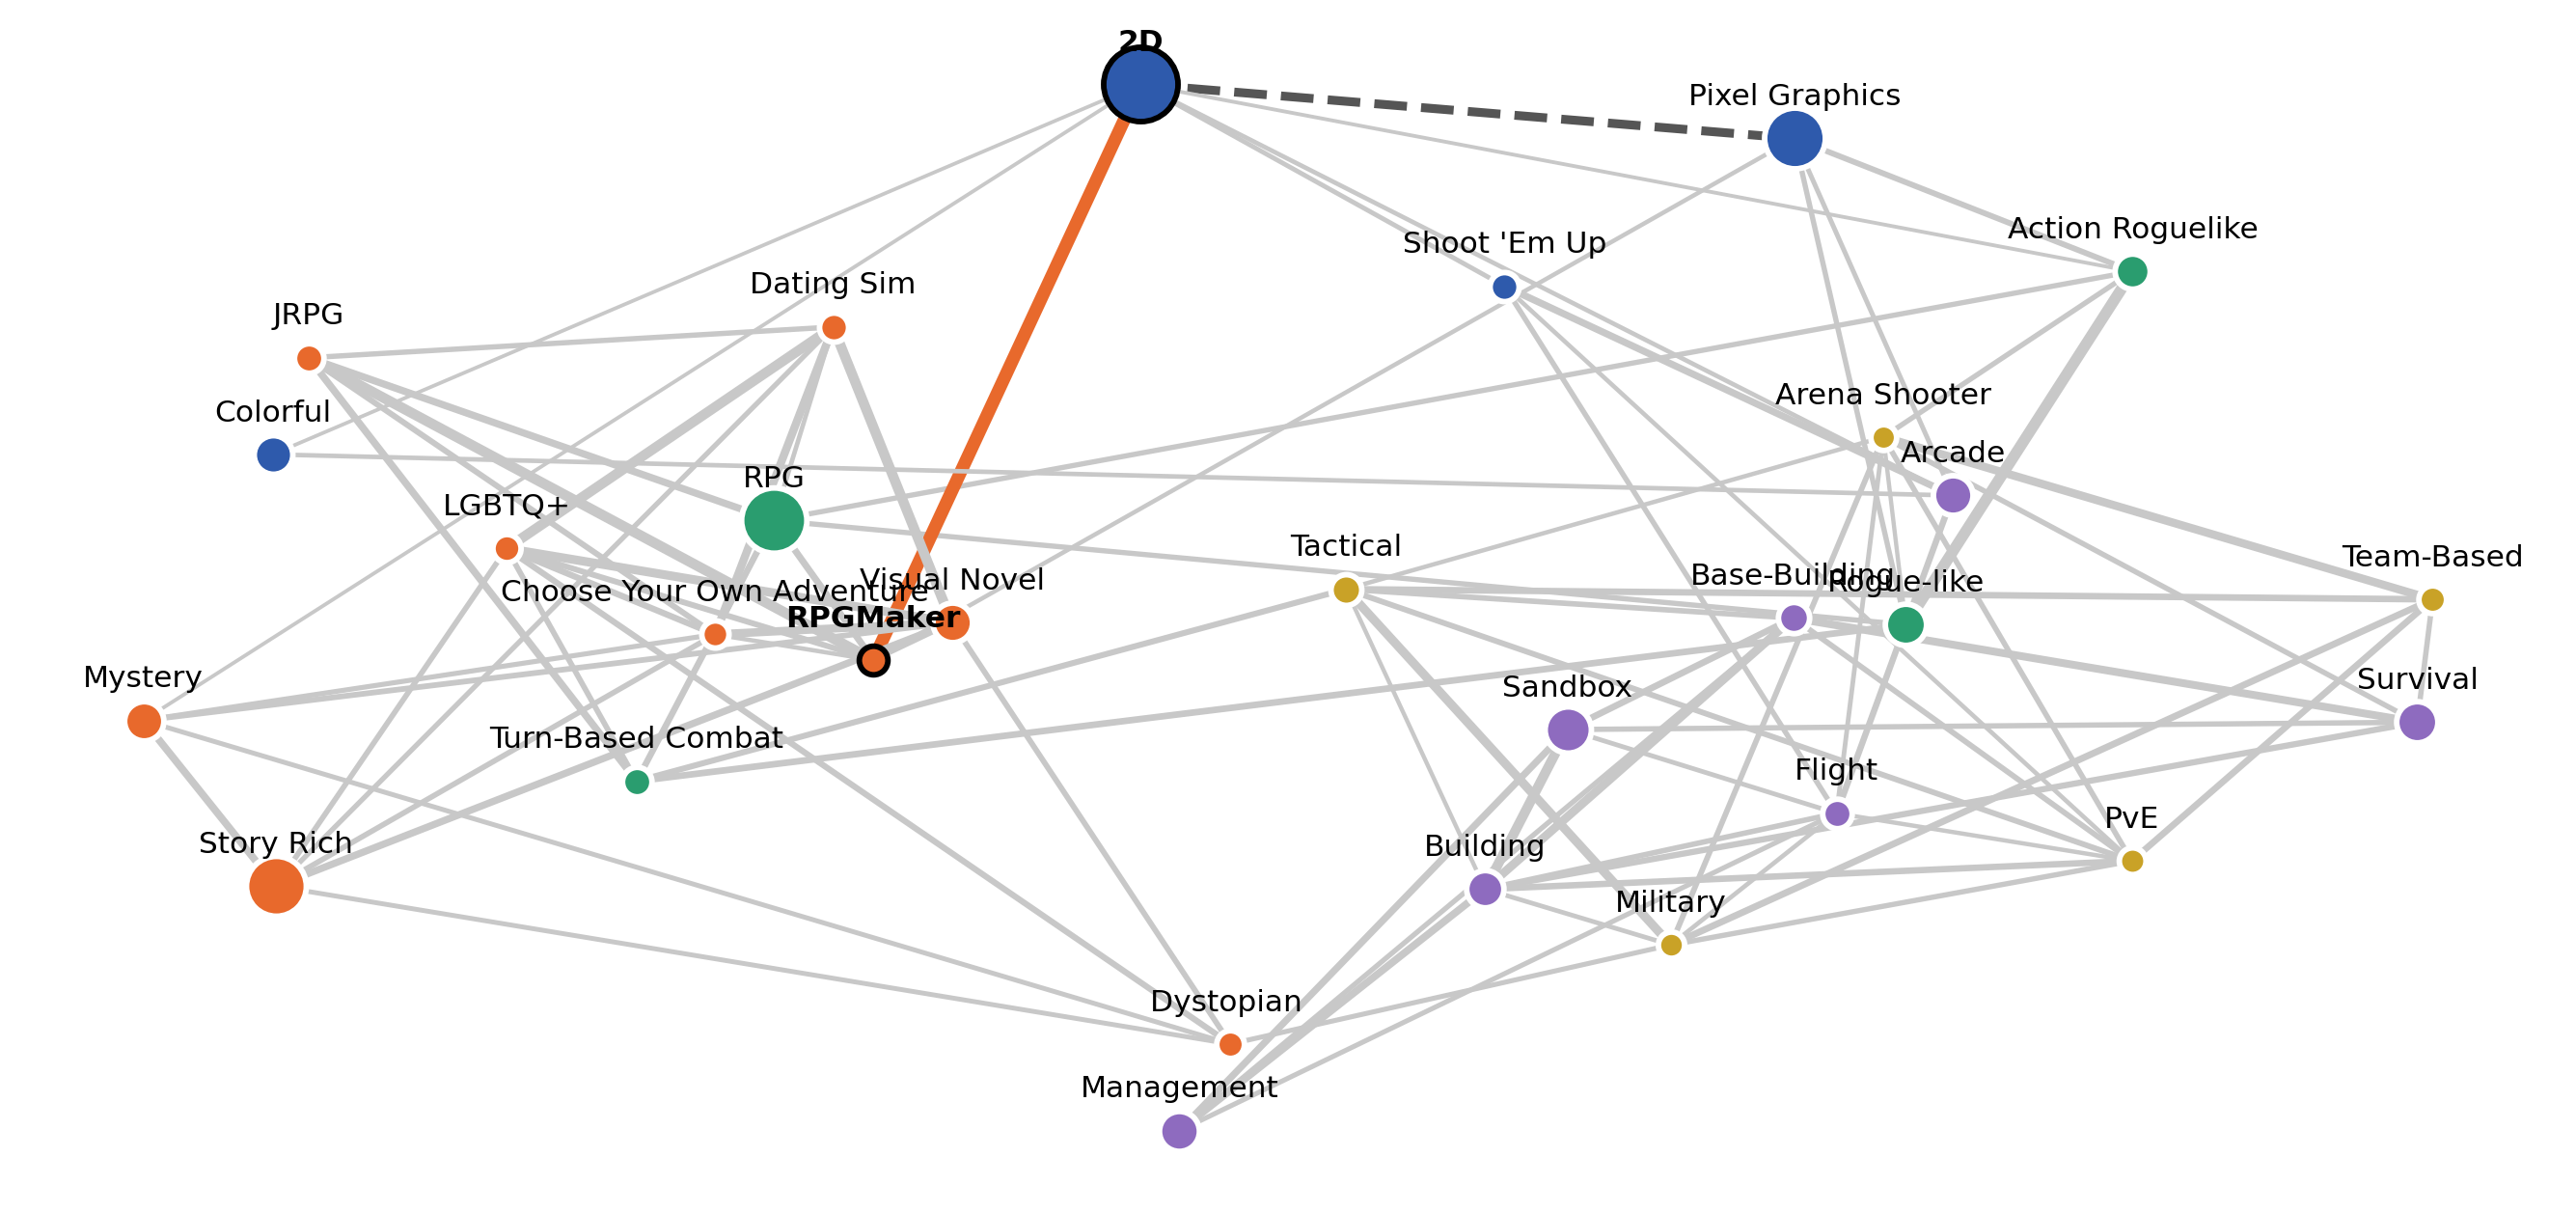

In [13]:
import matplotlib.pyplot as plt
top_nodes = sorted(G.nodes, key=lambda t: -G.degree(t, weight='npmi'))[:22]
nodes = set(top_nodes) | {CORE, PICK, CROWDED} | set(R.partner.head(5))
H = G.subgraph(nodes).copy()
H.remove_edges_from([(a, b) for a, b, d in H.edges(data=True) if d['npmi'] < 0.15 and CORE not in (a, b)])
H.remove_nodes_from(list(nx.isolates(H)))
pos = nx.spring_layout(H, weight='npmi', seed=7202, k=0.9)
pal = ['#2E5AAC', '#E8692C', '#2A9D6F', '#8E6BBF', '#C9A227', '#999999']
cmap = {c: pal[i % len(pal)] for i, c in enumerate(sorted(set(part[n] for n in H)))}
fig, ax = plt.subplots(figsize=(9, 4.3), dpi=300)
for a, b, d in H.edges(data=True):
    hl = {a, b} == {CORE, PICK}; cr = {a, b} == {CORE, CROWDED}
    ax.plot(*zip(pos[a], pos[b]), color='#E8692C' if hl else ('#555' if cr else '#C8C8C8'),
            lw=3.2 if hl else (2.2 if cr else 0.6 + 3 * d['npmi']), ls='--' if cr else '-', zorder=1)
for n in H:
    ax.scatter(*pos[n], s=25 + 1.6 * cnt[n], color=cmap[part[n]], edgecolor='black' if n in (CORE, PICK) else 'white', lw=1.4, zorder=2)
    ax.text(pos[n][0], pos[n][1] + 0.06, n, fontsize=7.5, ha='center', fontweight='bold' if n in (CORE, PICK) else 'normal', zorder=3)
ax.axis('off'); plt.tight_layout(); plt.savefig('figure.png', dpi=300, bbox_inches='tight'); plt.show()

## 11. Export results.json → send this file + figure.png back

In [14]:
res = dict(pull_date=PULL_DATE, seed=SEED_TAG, n_pool=int(len(pool)), n_sample=int(len(sample)), n_games=int(len(games)),
           min_reviews=MIN_REVIEWS, median_reviews=float(games.n_reviews.median()), median_score=float(games.score.median()),
           K=K, generic=[(t, round(prev[t], 3)) for t in generic], seed_prev=float(sum(SEED_TAG in t[:K] for t in games.tags) / len(games)),
           nodes=G.number_of_nodes(), edges=G.number_of_edges(), n_keep=n_keep, n_pairs=n_pairs,
           top_raw=[(a, b, d['count']) for a, b, d in top_raw], top_npmi=[(a, b, round(d['npmi'], 3), d['count']) for a, b, d in top_npmi],
           wdeg_raw=wdeg_raw, communities={str(c): sorted(ts, key=lambda t: -cnt[t])[:12] for c, ts in comms.items()},
           core=CORE, core_games=int(cnt[CORE]), pick=PICK, crowded=CROWDED,
           partners=R.round(4).to_dict('records'), sweep=sweep.to_dict('records'),
           bootstrap={k: v / B for k, v in tops.most_common(6)}, B=B,
           triang=dict(n=int(len(tri)), rho=None if rho is None else float(rho)),
           fig_nodes=H.number_of_nodes(), fig_edges=H.number_of_edges())
json.dump(res, open('results.json', 'w'), ensure_ascii=False, indent=1, default=str)
from google.colab import files
files.download('results.json'); files.download('figure.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
import json, collections, numpy as np, networkx as nx
from google.colab import files
Gd = G.copy()
for a, b, d in Gd.edges(data=True): d['dist'] = 1 / max(d['npmi'], 1e-6)
bc = nx.betweenness_centrality(Gd, weight='dist', normalized=True)
bc_rank = {t: i + 1 for i, (t, _) in enumerate(sorted(bc.items(), key=lambda x: -x[1]))}
def pcoef(t):
    k = sum(d['npmi'] for _, _, d in G.edges(t, data=True)); by = collections.Counter()
    for _, n, d in G.edges(t, data=True): by[part[n]] += d['npmi']
    return 1 - sum((v / k) ** 2 for v in by.values()), len(by)
out = {t: dict(bc=round(bc[t], 4), bc_rank=bc_rank[t], pc=round(pcoef(t)[0], 3), n_comms=pcoef(t)[1], degree=G.degree(t))
       for t in [CORE] + list(R.partner)}
out['_nodes'] = G.number_of_nodes(); out['_median_pc'] = round(float(np.median([pcoef(t)[0] for t in G])), 3)
print(json.dumps(out)); json.dump(out, open('structure.json', 'w')); files.download('structure.json')

{"2D": {"bc": 0.0015, "bc_rank": 146, "pc": 0.549, "n_comms": 5, "degree": 28}, "RPGMaker": {"bc": 0.0156, "bc_rank": 17, "pc": 0.342, "n_comms": 4, "degree": 25}, "Arcade": {"bc": 0.0126, "bc_rank": 34, "pc": 0.708, "n_comms": 4, "degree": 30}, "Mystery": {"bc": 0.0041, "bc_rank": 124, "pc": 0.269, "n_comms": 4, "degree": 27}, "Shoot 'Em Up": {"bc": 0.0038, "bc_rank": 125, "pc": 0.781, "n_comms": 5, "degree": 30}, "Colorful": {"bc": 0.0027, "bc_rank": 137, "pc": 0.613, "n_comms": 5, "degree": 29}, "Great Soundtrack": {"bc": 0.0006, "bc_rank": 154, "pc": 0.654, "n_comms": 3, "degree": 18}, "Minimalist": {"bc": 0.0135, "bc_rank": 28, "pc": 0.774, "n_comms": 5, "degree": 32}, "Bullet Hell": {"bc": 0.0131, "bc_rank": 31, "pc": 0.679, "n_comms": 4, "degree": 34}, "Action Roguelike": {"bc": 0.018, "bc_rank": 8, "pc": 0.5, "n_comms": 4, "degree": 30}, "Local Co-Op": {"bc": 0.0046, "bc_rank": 115, "pc": 0.622, "n_comms": 4, "degree": 26}, "Pixel Graphics": {"bc": 0.0031, "bc_rank": 133, "pc":

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
import re, json, time, random, requests
from google.colab import files
rb = requests.get('https://store.steampowered.com/robots.txt', headers=UA, timeout=30).text
print(rb[:600])
CK = {'birthtime': '0', 'lastagecheckage': '1-0-1970', 'mature_content': '1', 'wants_mature_content': '1'}
chk = []
for _, g in games.sample(30, random_state=2026).iterrows():
    try:
        h = requests.get(f"https://store.steampowered.com/app/{g.appid}/", headers=UA, cookies=CK, timeout=30).text
        store = [t.strip() for t in re.findall(r'class="app_tag"[^>]*>\s*([^<]+?)\s*</a>', h) if t.strip() != '+']
        if len(store) >= 5:
            s15, t15 = set(g.tags[:15]), set(store[:15])
            chk.append(dict(appid=int(g.appid), top5=len(set(g.tags[:5]) & set(store[:5])) / 5,
                            top15=len(s15 & t15) / 15, store_n=len(store)))
    except Exception as e:
        print('skip', g.appid, e)
    time.sleep(1.5)
tc = dict(n=len(chk), top5_match=round(float(np.mean([c['top5'] for c in chk])), 3),
          top15_match=round(float(np.mean([c['top15'] for c in chk])), 3), games=chk)
print(json.dumps({k: v for k, v in tc.items() if k != 'games'}))
json.dump(tc, open('tagcheck.json', 'w'), indent=1); files.download('tagcheck.json')

Host: store.steampowered.com
User-Agent: *
Disallow: /share/
Disallow: /news/externalpost/
Disallow: /account/emailoptout/?*token=
Disallow: /account/notificationsettings/?*token=
Disallow: /login/?*guestpasskey=
Disallow: /join/?*redir=
Disallow: /account/ackgift/
Disallow: /email/
Disallow: /widget/

{"n": 29, "top5_match": 0.828, "top15_match": 0.841}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>